Extraccion de datos usando FastF1

In [2]:
pip install fastf1

  Using cached fastf1-3.5.3-py3-none-any.whl.metadata (4.6 kB)
  Using cached requests_cache-1.2.1-py3-none-any.whl.metadata (9.9 kB)
  Using cached timple-0.1.8-py3-none-any.whl.metadata (2.0 kB)
  Using cached cattrs-25.1.1-py3-none-any.whl.metadata (8.4 kB)
  Using cached url_normalize-2.2.1-py3-none-any.whl.metadata (5.6 kB)
Using cached fastf1-3.5.3-py3-none-any.whl (151 kB)
Using cached requests_cache-1.2.1-py3-none-any.whl (61 kB)
Using cached timple-0.1.8-py3-none-any.whl (17 kB)
Using cached cattrs-25.1.1-py3-none-any.whl (69 kB)
Using cached url_normalize-2.2.1-py3-none-any.whl (14 kB)
Note: you may need to restart the kernel to use updated packages.


  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.


In [3]:
import seaborn as sns
from matplotlib import pyplot as plt

import fastf1
import fastf1.plotting


# Enable Matplotlib patches for plotting timedelta values and load
# FastF1's dark color scheme
fastf1.plotting.setup_mpl(mpl_timedelta_support=True, misc_mpl_mods=False,
                          color_scheme='fastf1')

In [32]:
race = fastf1.get_session(2019, "austin", 'R')
race.load()

core           INFO 	Loading data for United States Grand Prix - Race [v3.5.3]
req            INFO 	No cached data found for session_info. Loading data...
_api           INFO 	Fetching session info data...
req            INFO 	Data has been written to cache!
req            INFO 	No cached data found for driver_info. Loading data...
_api           INFO 	Fetching driver list...
req            INFO 	Data has been written to cache!
req            INFO 	No cached data found for session_status_data. Loading data...
_api           INFO 	Fetching session status data...
req            INFO 	Data has been written to cache!
req            INFO 	No cached data found for lap_count. Loading data...
_api           INFO 	Fetching lap count data...
req            INFO 	Data has been written to cache!
req            INFO 	No cached data found for track_status_data. Loading data...
_api           INFO 	Fetching track status data...
req            INFO 	Data has been written to cache!
req            INFO 

In [33]:
point_finishers = race.drivers[:10]
print(point_finishers)
driver_laps = race.laps.pick_drivers(point_finishers).pick_quicklaps()
driver_laps = driver_laps.reset_index()

['77', '44', '33', '16', '23', '3', '4', '55', '27', '11']


In [34]:
finishing_order = [race.get_driver(i)["Abbreviation"] for i in point_finishers]
print(finishing_order)

['BOT', 'HAM', 'VER', 'LEC', 'ALB', 'RIC', 'NOR', 'SAI', 'HUL', 'PER']


req            INFO 	Using cached data for driver_info


<Axes: xlabel='Driver', ylabel='LapTime(s)'>

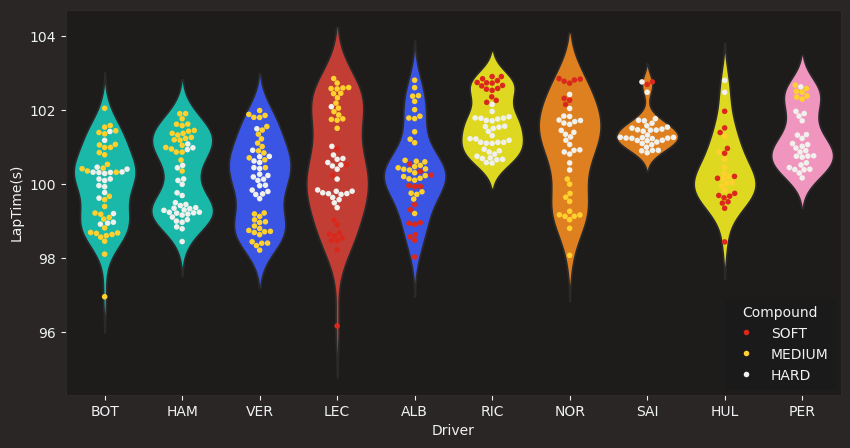

In [35]:
# create the figure
fig, ax = plt.subplots(figsize=(10, 5))

# Seaborn doesn't have proper timedelta support,
# so we have to convert timedelta to float (in seconds)
driver_laps["LapTime(s)"] = driver_laps["LapTime"].dt.total_seconds()

sns.violinplot(data=driver_laps,
               x="Driver",
               y="LapTime(s)",
               hue="Driver",
               inner=None,
               density_norm="area",
               order=finishing_order,
               palette=fastf1.plotting.get_driver_color_mapping(session=race)
               )

sns.swarmplot(data=driver_laps,
              x="Driver",
              y="LapTime(s)",
              order=finishing_order,
              hue="Compound",
              palette=fastf1.plotting.get_compound_mapping(session=race),
              hue_order=["SOFT", "MEDIUM", "HARD"],
              linewidth=0,
              size=4,
              )

logger      WARNING 	Failed to load schedule from FastF1 backend!
req            INFO 	No cached data found for season_schedule. Loading data...


_api           INFO 	Fetching season schedule...
req            INFO 	Data has been written to cache!
core           INFO 	Loading data for United States Grand Prix - Race [v3.5.3]
req            INFO 	Using cached data for session_info
req            INFO 	Using cached data for driver_info
req            INFO 	Using cached data for session_status_data
req            INFO 	Using cached data for lap_count
req            INFO 	Using cached data for track_status_data
req            INFO 	Using cached data for _extended_timing_data
req            INFO 	Using cached data for timing_app_data
core           INFO 	Processing timing data...
req            INFO 	Using cached data for race_control_messages
core           INFO 	Finished loading data for 20 drivers: ['16', '55', '1', '4', '81', '63', '11', '27', '30', '43', '20', '10', '14', '22', '18', '23', '77', '31', '24', '44']


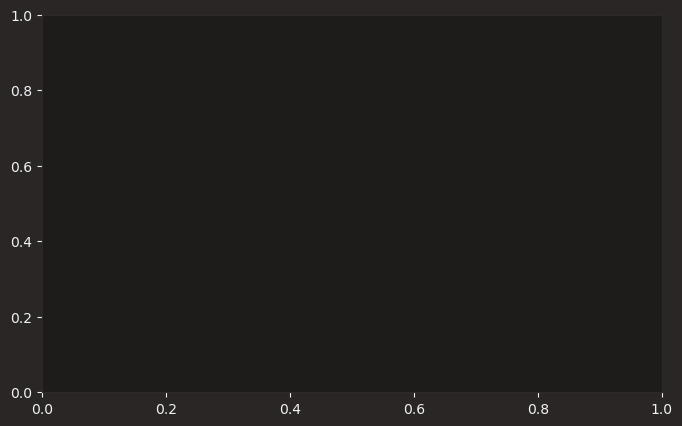

In [ ]:
session = fastf1.get_session(2024, 'austin', 'R')
session.load(telemetry=False, weather=False)



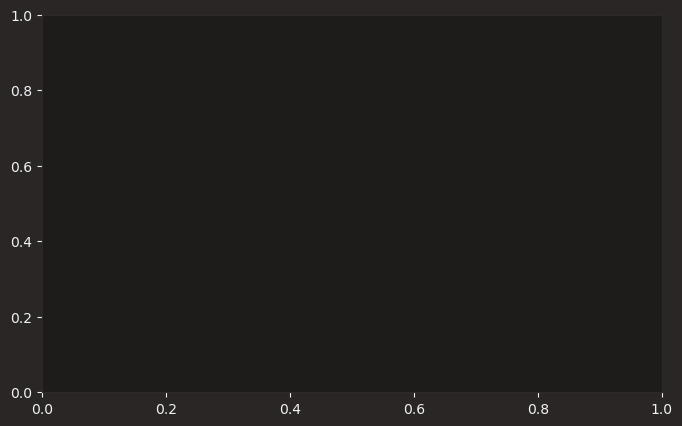

In [28]:
import matplotlib.pyplot as plt
fig, ax = plt.subplots(figsize=(8.0, 4.9))

In [29]:
for drv in session.drivers:
    drv_laps = session.laps.pick_drivers(drv)

    abb = drv_laps['Driver'].iloc[0]
    style = fastf1.plotting.get_driver_style(identifier=abb,
                                             style=['color', 'linestyle'],
                                             session=session)

    ax.plot(drv_laps['LapNumber'], drv_laps['Position'],
            label=abb, **style)

In [30]:
ax.set_ylim([20.5, 0.5])
ax.set_yticks([1, 5, 10, 15, 20])
ax.set_xlabel('Lap')
ax.set_ylabel('Position')

Text(4.444444444444445, 0.5, 'Position')

In [31]:
ax.legend(bbox_to_anchor=(1.0, 1.02))
plt.tight_layout()

plt.show()

<Figure size 640x480 with 0 Axes>